# 03 — Regressão linear múltipla (TP3)

**Projeto E-ComShield — fechamento do Trimestre 1**

Neste notebook ajusto uma **regressão linear múltipla** no dataset Bitext Retail eCommerce, mesmo sabendo que a
tarefa final do projeto é de *classificação* de intenção. O objetivo é exercitar o pipeline completo
(pré-processamento → modelo → métricas → diagnóstico de resíduos) e mostrar, com evidência, por que a regressão
linear **não** é a ferramenta certa para o problema final.

**Variável alvo (numérica derivada do texto):** `n_palavras` — número de palavras da mensagem do cliente (`instruction`).

**Preditores:** categoria (`category`, one-hot), flags de variação linguística do dataset (`tags`) e características
simples do texto (interrogação e proporção de maiúsculas). O comprimento em caracteres **não** entra como preditor, porque
seria quase um vazamento do alvo.

> **Uso de IA:** a estrutura e parte do código foram escritas com apoio de IA (Claude). Conferi as métricas e
> as interpretações depois de rodar o notebook.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Dados e variável alvo

In [2]:
df = pd.read_csv("data/bitext-retail-ecommerce-llm-chatbot-training-dataset.csv")
print(df.shape)
print("Valores ausentes:", int(df.isna().sum().sum()), "| Duplicatas em instruction:", int(df.duplicated("instruction").sum()))
df[["instruction", "intent", "category", "tags"]].head()

(44884, 5)
Valores ausentes: 0 | Duplicatas em instruction: 0


,instruction,intent,category,tags
0,I got to add an item to the cart,add_product,CART,BL
1,wanna add fucking products to the basket can h...,add_product,CART,BCIMQWZ
2,i have to add products to the basket i ned help,add_product,CART,BCMQZ
3,di like to add products to the cart could i ge...,add_product,CART,BCILMPQZ
4,"I need to add an item to the cart , where do I...",add_product,CART,BCILZ


count    44884.00
mean        11.80
std          2.91
min          1.00
25%         10.00
50%         12.00
75%         14.00
max         24.00
Name: n_palavras, dtype: float64


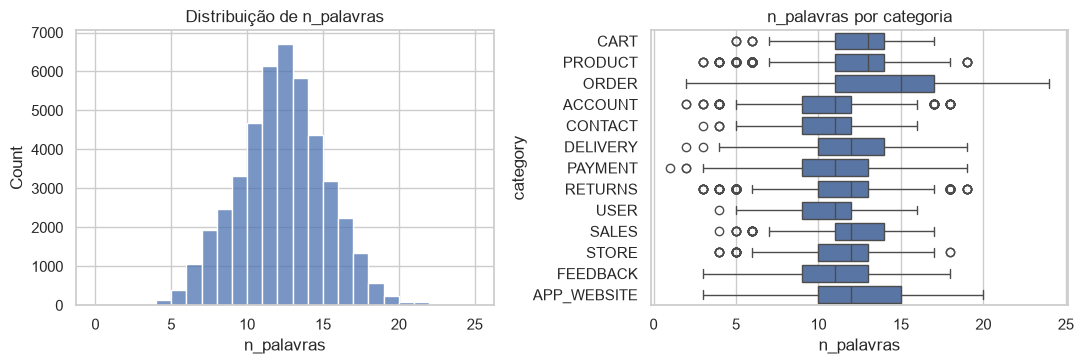

In [3]:
df["n_palavras"] = df["instruction"].str.split().str.len()
print(df["n_palavras"].describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df["n_palavras"], bins=range(0, 26), ax=ax[0])
ax[0].set_title("Distribuição de n_palavras")
sns.boxplot(data=df, y="category", x="n_palavras", ax=ax[1])
ax[1].set_title("n_palavras por categoria")
plt.tight_layout(); plt.show()

## 2. Engenharia de preditores

In [4]:
TAGS = list("CILMPQWZE")  # letras de variação linguística; "B" está em 100% das linhas (constante) e fica de fora

def build_features(d: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=d.index)
    X["category"] = d["category"]
    for t in TAGS:
        X[f"tag_{t}"] = d["tags"].str.contains(t).astype(int)
    txt = d["instruction"]
    X["tem_interrogacao"] = txt.str.contains(r"\?").astype(int)
    X["prop_maiusculas"] = txt.apply(lambda s: sum(c.isupper() for c in s) / max(len(s), 1))
    return X

X = build_features(df)
y = df["n_palavras"]
X.head()

,category,tag_C,tag_I,tag_L,tag_M,tag_P,tag_Q,tag_W,tag_Z,tag_E,tem_interrogacao,prop_maiusculas
0,CART,0,0,1,0,0,0,0,0,0,0,0.031250
1,CART,1,1,0,1,0,1,1,1,0,0,0.000000
2,CART,1,0,0,1,0,1,0,1,0,0,0.000000
3,CART,1,1,1,1,1,1,0,1,0,0,0.000000
4,CART,1,1,1,0,0,0,0,1,0,1,0.037736


## 3. Pipeline: pré-processamento + LinearRegression

In [5]:
cat_cols = ["category"]

pre = ColumnTransformer(
    [("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)],
    remainder="passthrough",
)
pipe = Pipeline([("pre", pre), ("reg", LinearRegression())])

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
pipe.fit(X_tr, y_tr)

pred_tr, pred_te = pipe.predict(X_tr), pipe.predict(X_te)
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))
metricas = pd.DataFrame({
    "R²": [r2_score(y_tr, pred_tr), r2_score(y_te, pred_te)],
    "RMSE (palavras)": [rmse(y_tr, pred_tr), rmse(y_te, pred_te)],
}, index=["treino", "teste"]).round(4)
baseline = rmse(y_te, np.full(len(y_te), y_tr.mean()))
print(metricas)
print(f"RMSE do baseline (sempre prever a média): {baseline:.4f}")

            R²  RMSE (palavras)
treino  0.5662           1.9151
teste   0.5607           1.9364
RMSE do baseline (sempre prever a média): 2.9214


## 4. Coeficientes

Intercepto: 5.784


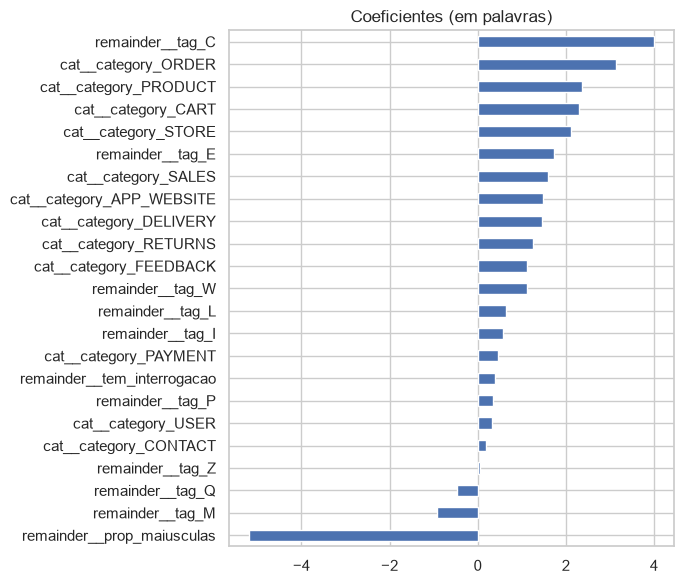

In [6]:
nomes = pipe.named_steps["pre"].get_feature_names_out()
coef = pd.Series(pipe.named_steps["reg"].coef_, index=nomes).sort_values()
print("Intercepto:", round(float(pipe.named_steps["reg"].intercept_), 3))
fig, ax = plt.subplots(figsize=(7, 6))
coef.plot.barh(ax=ax)
ax.set_title("Coeficientes (em palavras)"); plt.tight_layout(); plt.show()

## 5. Inferência com statsmodels (OLS)
Reajusto o mesmo modelo com `statsmodels` apenas para obter p-valores e testes de diagnóstico (o `sklearn` não os fornece).

In [7]:
X_sm = pd.get_dummies(X, columns=["category"], drop_first=True, dtype=float)
ols = sm.OLS(y, sm.add_constant(X_sm)).fit()
print(ols.summary().tables[0])
sig = ols.pvalues.drop("const")
print(f"\nPreditores com p<0,05: {(sig < 0.05).sum()} de {len(sig)}")
print(sig.sort_values().head(8).round(4))

                            OLS Regression Results                            
Dep. Variable:             n_palavras   R-squared:                       0.565
Model:                            OLS   Adj. R-squared:                  0.565
Method:                 Least Squares   F-statistic:                     2535.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:53:15   Log-Likelihood:                -92950.
No. Observations:               44884   AIC:                         1.859e+05
Df Residuals:                   44860   BIC:                         1.862e+05
Df Model:                          23                                         
Covariance Type:            nonrobust                                         

Preditores com p<0,05: 23 de 23
tag_C                0.0
tag_W                0.0
category_CART        0.0
tag_E                0.0
category_DELIVERY    0.0
category_ORDER       0.0
category_PRODUCT     0.0
ca

## 6. Análise de resíduos

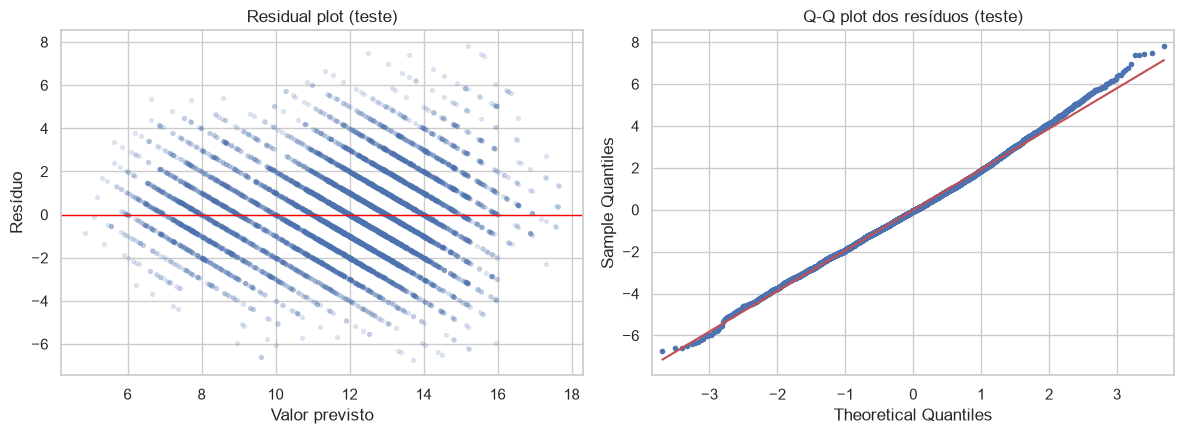

In [8]:
res = y_te - pred_te

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(pred_te, res, alpha=0.15, s=8)
ax[0].axhline(0, color="red", lw=1)
ax[0].set(title="Residual plot (teste)", xlabel="Valor previsto", ylabel="Resíduo")
sm.qqplot(res, line="s", ax=ax[1], markersize=3)
ax[1].set_title("Q-Q plot dos resíduos (teste)")
plt.tight_layout(); plt.show()

In [9]:
res_all = ols.resid
amostra = res_all.sample(5000, random_state=RANDOM_STATE)  # Shapiro é instável para n grande
print("Shapiro-Wilk (amostra de 5000): W=%.4f p=%.3g" % stats.shapiro(amostra))
print("Assimetria: %.3f | Curtose (excesso): %.3f" % (stats.skew(res_all), stats.kurtosis(res_all)))
bp = het_breuschpagan(res_all, ols.model.exog)
print("Breusch-Pagan (homocedasticidade): LM=%.2f p=%.3g" % (bp[0], bp[1]))
print("Durbin-Watson: %.3f" % durbin_watson(res_all))
print("Média dos resíduos: %.2e" % res_all.mean())

Shapiro-Wilk (amostra de 5000): W=0.9983 p=2.57e-05
Assimetria: 0.164 | Curtose (excesso): 0.289
Breusch-Pagan (homocedasticidade): LM=4856.34 p=0
Durbin-Watson: 1.451
Média dos resíduos: 8.69e-15


## 7. Multicolinearidade (VIF)

In [10]:
Xv = sm.add_constant(X_sm)
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=Xv.columns[1:]).sort_values(ascending=False)
print(vif.head(8).round(2))

tag_Q                4.82
tem_interrogacao     4.45
prop_maiusculas      2.44
tag_I                2.18
category_DELIVERY    2.10
category_PRODUCT     2.10
category_RETURNS     2.07
category_ORDER       1.66
dtype: float64


## 8. Interpretação, limitações e próximos passos

**O que os números mostram** (valores da execução acima)
- **Desempenho:** R² ≈ 0,56 no teste (0,57 no treino) e RMSE ≈ 1,94 palavras, contra 2,92 do baseline "prever a média". O modelo explica pouco mais da metade da variação do comprimento e reduz o erro em ~34%. Treino e teste quase iguais → sem overfitting.
- **Efeito dominante:** a flag `tag_C` (mensagens com essa variação) tem o maior coeficiente: na média, essas mensagens têm ~12,7 palavras contra ~8,3 sem a flag. As demais tags e as categorias têm efeitos menores, mas os 23 preditores saem com p < 0,05 — com n = 44.884 quase tudo é "significativo", então p-valor aqui diz pouco sobre relevância prática.
- **Residual plot:** resíduos centrados em zero, sem curvatura. As faixas diagonais aparecem porque o alvo é inteiro e os preditores são quase todos binários; não indicam erro de especificação.
- **Q-Q plot:** os resíduos seguem a reta, com desvio leve na cauda direita (assimetria 0,16; curtose em excesso 0,29). O Shapiro-Wilk rejeita normalidade (p ≈ 2,6e-05), mas W = 0,998, ou seja, o desvio é pequeno e o teste é sensível demais com amostra grande.
- **Breusch-Pagan:** p ≈ 0 → há heterocedasticidade (a dispersão dos resíduos muda com os preditores). Os erros-padrão e p-valores do OLS ficam pouco confiáveis; erros robustos (HC3) seriam o ajuste.
- **Durbin-Watson ≈ 1,45:** um pouco abaixo de 2, sugerindo leve autocorrelação positiva. Como as linhas são geradas em blocos por intenção, a ordem do arquivo pode ter estrutura; não embaralhei para o teste.
- **VIF:** o maior é ~4,8 (`tag_Q`, correlacionada com `tem_interrogacao`, r ≈ −0,73). Abaixo de 5–10, então multicolinearidade é moderada.

**Limitações**
1. **Alvo pouco interessante para o negócio.** Comprimento da mensagem não ajuda a entender a intenção do cliente.
2. **Dataset sintético.** O Bitext foi gerado por templates; o comprimento depende da *variação linguística* aplicada (as tags), não de comportamento real. Os resultados não se transferem automaticamente ao Shopzilla.
3. **Alvo discreto e positivo.** A regressão linear pode prever valores fracionários ou < 1.
4. **Pressupostos parcialmente violados:** heterocedasticidade e leve autocorrelação, como acima.
5. **Preditores quase todos binários** → poucos valores previstos distintos.
6. **Coeficientes são associações**, não causa. Também não conferi os significados exatos de cada letra de `tags` na documentação do Bitext.
7. **Não resolve o problema do projeto (classificar a intenção, 46 classes).** Motivos técnicos:
   - o alvo é **categórico nominal**: codificar intenções como 1…46 impõe uma ordem e uma distância que não existem;
   - a saída é um número contínuo e ilimitado, sem regra natural para virar uma classe;
   - não dá **probabilidade por intenção**, necessária para decidir quando escalar a um humano;
   - os pressupostos do OLS (erro normal, variância constante) e a perda quadrática não fazem sentido para rótulos discretos;
   - texto vira milhares de colunas TF-IDF esparsas, onde logística/SVM com perda de classificação e regularização funcionam melhor.
   Detalhes e distribuição das classes em `docs/pergunta-classificacao.md`.

**Próximos passos (T2)**
- Trocar para classificação supervisionada (regressão logística multinomial ou SVM linear) com TF-IDF — ver `docs/planejamento-t2.md`.
- Avaliar com acurácia, F1 macro, matriz de confusão e validação cruzada estratificada.
- Se for preciso um alvo contínuo (ex.: sentimento), usar erros robustos e validar no Shopzilla (CSAT).

## Uso de IA
Este notebook foi estruturado e codificado com apoio de IA (Claude). A execução, os números e as interpretações foram conferidos ao rodar o notebook localmente.